In [1]:
library(lme4)
library(lmerTest)
library(ggplot2)
library(mgcv)
library(plotly)
library(parallel)
library(MuMIn)
library(ggeffects)
library(car)
library(tidyr)
library(dplyr)
library(glmmTMB)
rescale_01 <- function(x) {
  (x - min(x, na.rm = TRUE)) / (max(x, na.rm = TRUE) - min(x, na.rm = TRUE))
}

residual_test <- function(model){
hist(residuals(model), main = "Histogram of Residuals", xlab = "Residuals")
qqnorm(residuals(model))
qqline(residuals(model), col = "red")
# shapiro.test(residuals(model))
ks.test(residuals(model), "pnorm", mean = mean(residuals(model)), sd = sd(residuals(model)))}

df <- read.csv("../../../data_processing/combine_data/results_aemri_combined.csv")

Loading required package: Matrix

Warning message:
“package ‘Matrix’ was built under R version 4.4.3”
Warning message:
“package ‘lmerTest’ was built under R version 4.4.3”

Attaching package: ‘lmerTest’


The following object is masked from ‘package:lme4’:

    lmer


The following object is masked from ‘package:stats’:

    step


Loading required package: nlme


Attaching package: ‘nlme’


The following object is masked from ‘package:lme4’:

    lmList


This is mgcv 1.9-1. For overview type 'help("mgcv-package")'.


Attaching package: ‘plotly’


The following object is masked from ‘package:ggplot2’:

    last_plot


The following object is masked from ‘package:stats’:

    filter


The following object is masked from ‘package:graphics’:

    layout


Loading required package: carData


Attaching package: ‘tidyr’


The following objects are masked from ‘package:Matrix’:

    expand, pack, unpack



Attaching package: ‘dplyr’


The following object is masked from ‘package:car’:

    r

In [2]:
df <- df[!df$cross_syllable_boundary, ]
df <- df[df$data_space=="raw", ]

df[df$modality=="art",]$dist <- scale(df[df$modality=="art",]$dist)
df[df$modality=="ac",]$dist <- scale(df[df$modality=="ac",]$dist)

df$phone1_H_art_given_ac <- scale(df$phone1_H_art_given_ac)
df$phone2_H_art_given_ac <- scale(df$phone2_H_art_given_ac)
df$phone2_freq <- scale(log(df$phone2_freq))
df$bigram_surprisal <- as.numeric(scale(df$bigram_surprisal))

df$subject <- as.factor(df$subject)
df$word <- as.factor(df$word)
df$bigram <- as.factor(paste(df$phone1, df$phone2, sep = "_"))

df$token_id <- as.factor(paste(df$word_id, df$phone1_start, sep = "_"))

df$modality <- as.factor(df$modality)
contrasts(df$modality) <- c(-0.5, 0.5)
print(contrasts(df$modality))
print("n rows:")
print(nrow(df))

df$phone2_duration <- df$phone2_end - df$phone2_start
df$phone2_duration <- scale(df$phone2_duration)

    [,1]
ac  -0.5
art  0.5
[1] "n rows:"
[1] 208430


In [ ]:
model <- lmer(
  dist ~ bigram_surprisal *
         modality *

         phone2_H_art_given_ac *
         phone1_H_art_given_ac *

         phone2_duration *

         phone2_freq +
    (1 | token_id) +
    (bigram_surprisal | word) + 
    (bigram_surprisal | bigram) + 
    (bigram_surprisal | subject),
  data = df,
  control = lmerControl(
    optimizer = "bobyqa",
    optCtrl = list(maxfun = 2e5)
  )
)
summary(model)

 Family: gaussian  ( identity )
Formula:          dist ~ bigram_surprisal * modality * phone2_H_art_given_ac +  
    phone1_H_art_given_ac + phone2_duration + phone2_freq + (1 |  
    token_id) + (bigram_surprisal + modality || subject) + (bigram_surprisal +  
    modality || word) + (bigram_surprisal + modality || bigram)
Dispersion:            ~modality
Data: df

      AIC       BIC    logLik  deviance  df.resid 
 428880.8  429114.1 -214417.4  428834.8    188030 

Random effects:

Conditional model:
 Groups   Name             Variance  Std.Dev. Corr      
 token_id (Intercept)      0.0782515 0.27973            
 subject  (Intercept)      2.3502600 1.53306            
          bigram_surprisal 0.0005275 0.02297  0.00      
          modality1        0.1519766 0.38984  0.00 0.00 
 word     (Intercept)      0.0594951 0.24392            
          bigram_surprisal 0.0267173 0.16345  0.00      
          modality1        0.1358993 0.36865  0.00 0.00 
 bigram   (Intercept)      0.1015041 

In [4]:
library(emmeans)
tr <- emtrends(model, ~ modality, var = "bigram_surprisal")
summary(tr, infer = c(TRUE, TRUE))

Welcome to emmeans.
Caution: You lose important information if you filter this package's results.
See '? untidy'

NOTE: Results may be misleading due to involvement in interactions



,modality,bigram_surprisal.trend,SE,df,lower.CL,upper.CL,t.ratio,p.value
,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,ac,0.12440228,0.01036564,188030,0.10408587,0.1447187,12.001410,3.591971e-33
2,art,0.08308531,0.01029000,188030,0.06291715,0.1032535,8.074372,6.822108e-16


In [ ]:
get_term_base <- function(model, term_name) {
  coef_table <- summary(model)$coefficients
  estimate <- coef_table[term_name, "Estimate"]
  p_value <- if(length(grep("Pr\\(>|p-value", colnames(coef_table), value = TRUE)) > 0) coef_table[term_name, grep("Pr\\(>|p-value", colnames(coef_table), value = TRUE)] else NA
  return(list(sign = ifelse(estimate > 0, "+", "-"), p_value = p_value,significant = (!is.na(p_value) && p_value < 0.05)))
}
get_term_base(model, "bigram_surprisal")
get_term_base(model, "bigram_surprisal:modality1:phone2_H_art_given_ac")

$sign
[1] "+"

$estimate
[1] 0.102616

$p_value
[1] 7.315688e-25

$significant
[1] TRUE

$sign
[1] "-"

$estimate
[1] -0.04425722

$p_value
[1] 1.634865e-23

$significant
[1] TRUE

In [ ]:
qs <- quantile(df$phone2_H_art_given_ac,
               probs = c(0, 0.25, 0.5, 0.75, 1),
               na.rm = TRUE)
vals <- as.numeric(qs)   # convert named quantile vector to numeric


preds <- ggpredict(model, terms = c("bigram_surprisal", "modality [ac, art]"))

preds$group <- factor(preds$group,
                      labels = c("ac", "art"))

p <- plot(preds) + labs(color = "Modality") + xlab("Phoneme bigram surprisal (z-scored)") + ylab("Predicted distinctiveness (z-scored)") + ggtitle(NULL) + ylim(-0.75, 1.25)
p
# write.csv(preds, "preds_surprisal.csv", row.names = FALSE)

preds <- ggpredict(model, terms = c("bigram_surprisal", sprintf("phone2_H_art_given_ac [%s]",
            paste(round(vals, 4), collapse = ", ")), "modality [ac]"))

preds$group <- factor(preds$group,
                      labels = c("Min", "Q1", "Q2", "Q3", "Max"))

p <- plot(preds) +
  labs(color = "Target phoneme flexibility\n(z-scored)") +
  xlab("Phoneme bigram surprisal (z-scored)") +
  ylab("Predicted acoustic distinctiveness\n(z-scored)") +
  ggtitle(NULL) +
  ylim(-0.75, 1.25) +
  scale_color_viridis_d(option = "viridis") +
  scale_fill_viridis_d(option = "viridis") +
  theme_minimal(base_size = 16)

# ggsave("acousticplot.png", plot = p, width = 8, height = 4.3, dpi = 300)
p
# write.csv(preds, "../preds_acoustics.csv", row.names = FALSE)


preds <- ggpredict(model, terms = c("bigram_surprisal", sprintf("phone2_H_art_given_ac [%s]",
            paste(round(vals, 4), collapse = ", ")), "modality [art]"))

preds$group <- factor(preds$group,
                      labels = c("Min", "Q1", "Q2", "Q3", "Max"))

p <- plot(preds) +
  labs(color = "Target phoneme flexibility\n(z-scored)") +
  xlab("Phoneme bigram surprisal (z-scored)") +
  ylab("Predicted articulatory distinctiveness\n(z-scored)") +
  ggtitle(NULL) +
  ylim(-0.75, 1.25) +
  scale_color_viridis_d(option = "viridis") +
  scale_fill_viridis_d(option = "viridis") +
  theme_minimal(base_size = 16)

# ggsave("articulatoryplot.png", plot = p, width = 8, height = 4.3, dpi = 300)
p
# write.csv(preds, "../preds_articulatory.csv", row.names = FALSE)

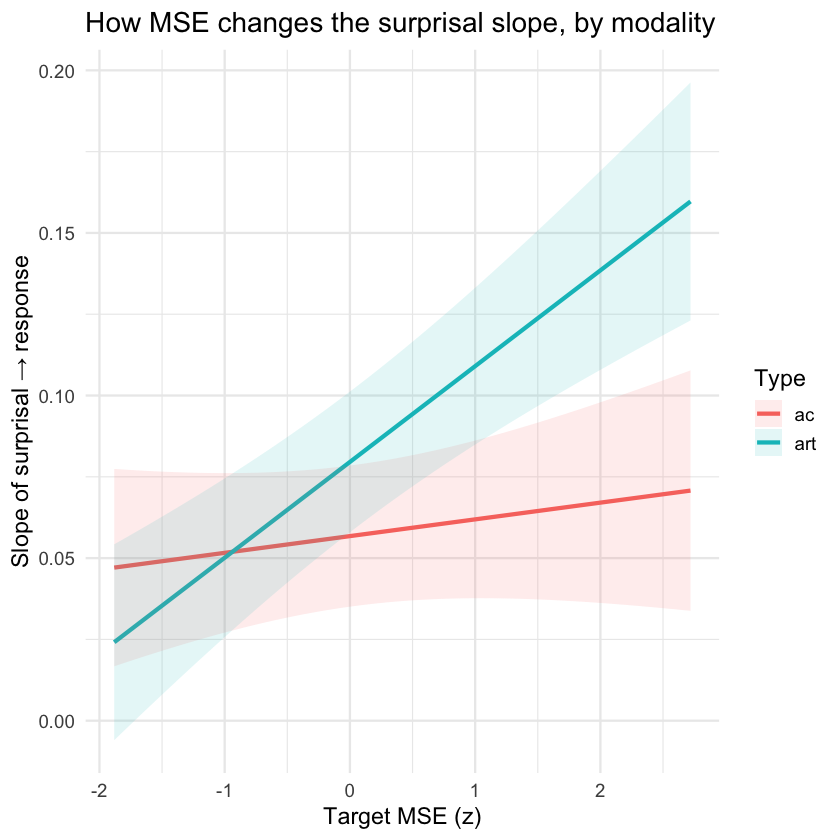

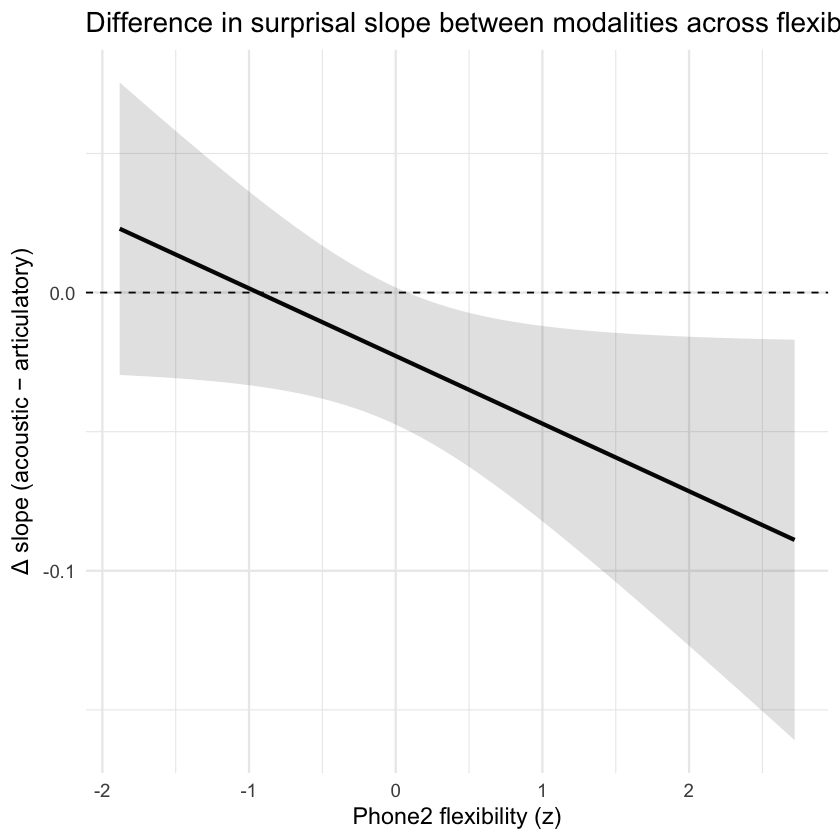

In [ ]:
library(emmeans)
library(dplyr)
library(ggplot2)

# 1) Slopes (trends) of surprisal across a smooth MSE grid
mse_grid <- seq(min(df$phone2_H_art_given_ac, na.rm = TRUE),
                max(df$phone2_H_art_given_ac, na.rm = TRUE),
                length.out = 75)

em_curve <- emtrends(
  model,
  specs = ~ modality * phone2_H_art_given_ac,
  var   = "bigram_surprisal",
  at    = list(phone2_H_art_given_ac = mse_grid)
)

curve_df <- as.data.frame(em_curve) %>%
  # emtrends names the slope column like "surprisal.trend"
  rename(slope = !!grep("trend$", names(.), value = TRUE),
         mse   = phone2_H_art_given_ac)

ggplot(curve_df, aes(x = mse, y = slope, color = modality)) +
  geom_line(size = 1.2) +
  geom_ribbon(aes(ymin = slope - SE, ymax = slope + SE, fill = modality),
              alpha = 0.12, color = NA) +
  labs(x = "Target MSE (z)",
       y = "Slope of surprisal → response",
       color = "Type", fill = "Type",
       title = "How MSE changes the surprisal slope, by modality") +
  theme_minimal(base_size = 14)

diff_curve <- contrast(
  em_curve,
  method = "pairwise",                    # (acoustic - articulatory)
  by     = "phone2_H_art_given_ac"
)

diff_df <- as.data.frame(diff_curve, infer = c(TRUE, TRUE)) %>%
  dplyr::rename(delta_slope = estimate,
                mse         = phone2_H_art_given_ac)

ggplot(diff_df, aes(x = mse, y = delta_slope)) +
  geom_hline(yintercept = 0, linetype = 2) +
  geom_line(size = 1.2) +
  geom_ribbon(aes(ymin = lower.CL, ymax = upper.CL), alpha = 0.15) +
  labs(x = "Phone2 flexibility (z)",
       y = "Δ slope (acoustic − articulatory)",
       title = "Difference in surprisal slope between modalities across flexibility") +
  theme_minimal(base_size = 14)
# write.csv(diff_df, "../diff_df.csv", row.names = FALSE)